<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-06/conditional-generation.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Conditional generation

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

A conditional variational autoencoder (VAE) learns $p_\theta(\mathbf x\,|\,\mathbf c)$, the distribution of images $\mathbf x$ of a given class $\mathbf c$. Before using it, we look at the logic of the VAE in a two-dimensional latent space, where the latent representation, the reparametrisation trick and the effect of conditioning can all be drawn.

With this in place, the notebook does two things. It **generates** new images of a class we choose, a digit from 0 to 9 from MNIST and a blood-cell type from BloodMNIST. It then **checks** them with a classifier trained on **real** images only, asking whether the classifier recognises the synthetic images as the requested class. The answer is a confusion matrix of *requested class* against *predicted class*, which we place next to the confusion matrix of the same classifier on real test images. Finally, we ask whether synthetic images can replace real ones, by training a classifier on synthetic images only and testing it on real ones.

Everything runs on a CPU (central processing unit) in a few minutes, and the trained weights are saved in `results/`.

The first code cell holds the imports and a few shared definitions: the computation is restricted to the CPU with four threads, figures for the slides go to `../beamer/figures`, numbers quoted on the slides are collected in the dictionary `nums` and saved to `results/`, and the function `seed` fixes the random generators of PyTorch and NumPy.

In [1]:
import os, json, time, gzip, urllib.request
os.environ["CUDA_VISIBLE_DEVICES"] = ""
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(4)
import os
OUT = "figures"; os.makedirs(OUT, exist_ok=True); os.makedirs(OUT, exist_ok=True)      # figures of the slides
RES = "results"; os.makedirs(RES, exist_ok=True)
blue, orange, navy = "#005CA7", "#EB6709", "#0A2F5C"
nums = {}                                                        # numbers quoted on the slides
def clean(ax):
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
def seed(k):
    torch.manual_seed(k); return np.random.default_rng(k)

## MNIST data

The MNIST (Modified National Institute of Standards and Technology) data set contains $28\times28$ images of handwritten digits labelled with the digit, from 0 to 9. The pixels are scaled to the interval from 0 to 1, so each image is a vector of 784 numbers. The files are read from `data/MNIST_raw` and downloaded once if missing.

In [2]:
RAW = "data/MNIST_raw"; os.makedirs(RAW, exist_ok=True)
LOCAL = os.path.expanduser("~/.pytorch/MNIST_data/MNIST/raw")
MIRRORS = ["https://ossci-datasets.s3.amazonaws.com/mnist/", "https://storage.googleapis.com/cvdf-datasets/mnist/"]
def mnist_file(name):
    for d in (RAW, LOCAL):
        p = os.path.join(d, name)
        if os.path.exists(p): return open(p, "rb").read()
        if os.path.exists(p + ".gz"): return gzip.open(p + ".gz").read()
    for m in MIRRORS:
        try:
            urllib.request.urlretrieve(m + name + ".gz", os.path.join(RAW, name + ".gz"))
            return gzip.open(os.path.join(RAW, name + ".gz")).read()
        except Exception: pass
    raise RuntimeError("MNIST could not be found or downloaded")
def idx(name):
    d = mnist_file(name)
    if d[3] == 3:
        n, r, c = np.frombuffer(d[4:16], ">i4"); return np.frombuffer(d[16:], np.uint8).reshape(n, r * c)
    return np.frombuffer(d[8:], np.uint8)
Xtr = torch.tensor(idx("train-images-idx3-ubyte").astype(np.float32) / 255); ytr = torch.tensor(idx("train-labels-idx1-ubyte").astype(np.int64))
Xte = torch.tensor(idx("t10k-images-idx3-ubyte").astype(np.float32) / 255); yte = torch.tensor(idx("t10k-labels-idx1-ubyte").astype(np.int64))
print("training images:", tuple(Xtr.shape), " test images:", tuple(Xte.shape))

training images: (60000, 784)  test images: (10000, 784)


## Variational autoencoder in a two-dimensional latent space

An encoder compresses an image $\mathbf x$, a vector of 784 pixel values, into a few numbers $\mathbf z$, its *latent representation*: coordinates in which similar images are close. A decoder $G$ maps $\mathbf z$ back to an image. With two latent numbers the latent space can be drawn.

A plain autoencoder sends $\mathbf x$ to a single point. A VAE instead sends it to a Gaussian cloud,
$$q_\phi(\mathbf z\,|\,\mathbf x)=\mathcal N\big(\boldsymbol\mu(\mathbf x),\operatorname{diag}\boldsymbol\sigma^2(\mathbf x)\big): \tag{1}$$
the encoder outputs the centre $\boldsymbol\mu$ and the widths $\boldsymbol\sigma$, the latter as $\log\boldsymbol\sigma^2$, which can take any sign. In training, a random point of the cloud is decoded, so *every* point near $\boldsymbol\mu(\mathbf x)$ must decode to something like $\mathbf x$.

The loss has two terms per image,
$$\mathcal L(\mathbf x)=\underbrace{-\sum_{j=1}^{784}\big[x_j\log\hat x_j+(1-x_j)\log(1-\hat x_j)\big]}_{\text{reconstruction: } -\log p_\theta(\mathbf x|\mathbf z)}+\underbrace{\tfrac12\sum_{k=1}^{d}\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big)}_{\mathrm{KL}(q_\phi(\mathbf z|\mathbf x)\,\|\,\mathcal N(0,I))},\qquad \hat{\mathbf x}=\operatorname{sigmoid}\big(G(\mathbf z)\big), \tag{2}$$
with $d$ the number of latent coordinates. The first term is the binary cross-entropy between the image and its reconstruction. The second, the Kullback–Leibler (KL) divergence, pulls every cloud towards the standard Gaussian $\mathcal N(0,I)$, so that the clouds of all training images together fill it without gaps. A latent vector drawn at random from $\mathcal N(0,I)$ then lands where the decoder was trained, and this is what makes **generation** possible.

One obstacle remains: drawing $\mathbf z$ from the cloud has no derivative with respect to $\boldsymbol\mu$ and $\boldsymbol\sigma$. The reparametrisation trick removes it by writing
$$\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon,\qquad\boldsymbol\varepsilon\sim\mathcal N(0,I). \tag{3}$$
The randomness is now an input $\boldsymbol\varepsilon$ that does not depend on the weights, with the derivatives
$$\frac{\partial z_k}{\partial\mu_k}=1,\qquad \frac{\partial z_k}{\partial\sigma_k}=\varepsilon_k, \tag{4}$$
and backpropagation runs through $\mathbf z$ into the encoder.

The class `VAE` serves both for the plain VAE (`cond=0`) and for the conditional VAE (`cond=10`, with the condition concatenated to the inputs of both networks). The first model is a plain VAE with two latent numbers, trained for 20 epochs.

In [3]:
def mlp(sizes):
    layers = []
    for a, b in zip(sizes[:-1], sizes[1:]): layers += [nn.Linear(a, b), nn.ReLU()]
    return nn.Sequential(*layers[:-1])

class CVAE(nn.Module):
    # VAE with dense layers; cond > 0 makes it conditional: c is concatenated to the inputs of encoder and decoder
    def __init__(self, D=784, d=8, cond=10, hidden=(512, 256)):
        super().__init__()
        self.d, self.cond = d, cond
        self.enc = mlp([D + cond, *hidden]); self.enc.append(nn.ReLU())
        self.mu, self.logvar = nn.Linear(hidden[-1], d), nn.Linear(hidden[-1], d)
        self.dec = mlp([d + cond, *hidden[::-1], D])                  # logits of the pixels
    def encode(self, x, c=None):
        h = self.enc(x if c is None else torch.cat([x, c], 1)); return self.mu(h), self.logvar(h)
    def decode(self, z, c=None):
        return self.dec(z if c is None else torch.cat([z, c], 1))
    def forward(self, x, c=None):
        mu, logvar = self.encode(x, c)
        eps = torch.randn_like(mu)                                    # the randomness, outside the network
        z = mu + torch.exp(0.5 * logvar) * eps                        # reparametrisation trick
        return self.decode(z, c), mu, logvar

def vae_loss(logits, x, mu, logvar):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)
    kl = 0.5 * (mu ** 2 + logvar.exp() - logvar - 1).sum() / len(x)
    return rec + kl, rec, kl

def train_vae(model, X, C=None, epochs=20, lr=1e-3, bs=128):
    opt = torch.optim.Adam(model.parameters(), lr)
    for ep in range(epochs):
        perm = torch.randperm(len(X)); tot = np.zeros(3)
        for i in range(0, len(perm), bs):
            j = perm[i:i + bs]; c = None if C is None else C[j]
            logits, mu, logvar = model(X[j], c)
            loss, rec, kl = vae_loss(logits, X[j], mu, logvar)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += np.array([loss.item(), rec.item(), kl.item()]) * len(j)
        if ep % 5 == 4: print(f"epoch {ep + 1}: loss per image {tot[0] / len(X):.1f} = reconstruction {tot[1] / len(X):.1f} + KL {tot[2] / len(X):.1f}")
    return model.eval()

rng = seed(10); t0 = time.time()
vae2 = train_vae(CVAE(d=2, cond=0), Xtr, epochs=20)
torch.save(vae2.state_dict(), f"{RES}/cond_mnist_vae_d2.pt")
print(f"VAE with d = 2 trained in {time.time() - t0:.0f} s")

epoch 5: loss per image 148.0 = reconstruction 141.9 + KL 6.1


epoch 10: loss per image 142.5 = reconstruction 136.1 + KL 6.4


epoch 15: loss per image 140.3 = reconstruction 133.7 + KL 6.6


epoch 20: loss per image 138.7 = reconstruction 132.0 + KL 6.7
VAE with d = 2 trained in 184 s


### Latent space

After 20 epochs the loss per image is 138.7, of which 132.0 is reconstruction and 6.7 the KL term. Each test digit is encoded to the centre $\boldsymbol\mu(\mathbf x)$ of its cloud, a point in the plane, and coloured by its label. The VAE never saw these labels; they serve only to read the picture. The dashed circles mark radius 1 and 2 of $\mathcal N(0,I)$.

In [4]:
with torch.no_grad(): mu_te, lv_te = vae2.encode(Xte)
mu_te, sd_te = mu_te.numpy(), torch.exp(0.5 * lv_te).numpy()
nums["vae2_mean_sigma"] = float(sd_te.mean())
r_te = np.linalg.norm(mu_te, axis=1)
for r in (1, 2, 3): nums[f"vae2_frac_within_{r}"] = float((r_te < r).mean())
cm10 = plt.get_cmap("tab10")
fig, ax = plt.subplots(figsize=(5.6, 5.2))
for k in range(10):
    m = yte.numpy() == k
    ax.scatter(*mu_te[m].T, s=2, color=cm10(k), label=str(k))
for r in (1, 2): ax.add_patch(plt.Circle((0, 0), r, fill=False, ls="--", color="grey", lw=1))
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$")
ax.legend(markerscale=6, frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1, 0.5), title="digit")
ax.set_title(r"VAE latent space: $\boldsymbol{\mu}(\mathbf{x})$ of 10 000 test digits", fontsize=11); clean(ax)
plt.savefig(f"{OUT}/cond_vae_latent.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"mean width sigma of the clouds: {sd_te.mean():.3f};  spread of the centres (std of mu): {mu_te.std(0).round(2)}")
print("fraction of centres within radius 1, 2, 3:", [round(nums[f"vae2_frac_within_{r}"], 3) for r in (1, 2, 3)], " (N(0,I) in 2D: 0.393, 0.865, 0.989)")

mean width sigma of the clouds: 0.041;  spread of the centres (std of mu): [1.03 1.1 ]
fraction of centres within radius 1, 2, 3: [0.488, 0.797, 0.965]  (N(0,I) in 2D: 0.393, 0.865, 0.989)


/tmp/ipykernel_3978098/1925286077.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.savefig(f"{OUT}/cond_vae_latent.png", dpi=170, bbox_inches="tight"); plt.show()


Digits of the same class sit together, although no label was used in training. The clouds are narrow, with a mean width of 0.041, and their centres are concentrated around the origin, where $\mathcal N(0,I)$ puts its probability: 48.8%, 79.7% and 96.5% of them lie within radius 1, 2 and 3, against 39.3%, 86.5% and 98.9% for $\mathcal N(0,I)$ in two dimensions. The KL term pulls the clouds towards the origin, the reconstruction term pushes the classes apart, and some classes (0, 1, 7) sit at the edge.

### Reparametrisation trick

To see what the decoder must learn for a single input, we take one test image and let the encoder give its cloud $(\boldsymbol\mu,\boldsymbol\sigma)$. Eight noise vectors $\boldsymbol\varepsilon$ are drawn from $\mathcal N(0,I)$, turned into latent vectors by equation (3), and decoded: these are the images the decoder must produce during training for this one input. Automatic differentiation computes the derivatives of $z_1$ with respect to $\mu_1$ and $\sigma_1$, to be compared with equation (4).

In [5]:
# a test digit 0 that the 2D VAE rebuilds well: the smallest reconstruction error among the 0s
with torch.no_grad():
    zeros = (yte == 0).nonzero()[:, 0]
    rec0 = F.binary_cross_entropy_with_logits(vae2.decode(vae2.encode(Xte[zeros])[0]), Xte[zeros], reduction="none").sum(1)
i0 = int(zeros[rec0.argmin()])
with torch.no_grad():
    mu0, lv0 = vae2.encode(Xte[i0:i0 + 1]); sd0 = torch.exp(0.5 * lv0)
    torch.manual_seed(40); eps = torch.randn(8, 2)
    z8 = mu0 + sd0 * eps                                          # reparametrisation: z = mu + sigma * eps
    dec8 = torch.sigmoid(vae2.decode(z8)).reshape(-1, 28, 28).numpy()
fig = plt.figure(figsize=(11, 3.6))
a0 = fig.add_axes([0.0, 0.08, 0.17, 0.8]); a0.imshow(Xte[i0].reshape(28, 28), cmap="gray_r"); a0.axis("off"); a0.set_title("input $\\mathbf{x}$", fontsize=11)
a1 = fig.add_axes([0.22, 0.12, 0.28, 0.78])
a1.scatter(*mu_te.T, s=1, color="lightgrey")
from matplotlib.patches import Ellipse
for nsd in (1, 2): a1.add_patch(Ellipse(mu0[0].numpy(), 2 * nsd * sd0[0, 0].item(), 2 * nsd * sd0[0, 1].item(), fill=False, color=orange, lw=1.5))
a1.scatter(*z8.numpy().T, s=25, color=navy, zorder=3); a1.scatter(*mu0.numpy().T, s=60, marker="x", color=orange, zorder=4)
for j, (a_, b_) in enumerate(z8.numpy()): a1.annotate(str(j + 1), (a_, b_), xytext=(3, 3), textcoords="offset points", fontsize=8)
c0 = mu0[0].numpy(); w0 = 4 * max(sd0[0].tolist()) + 0.3
a1.set_xlim(c0[0] - w0, c0[0] + w0); a1.set_ylim(c0[1] - w0, c0[1] + w0); a1.set_aspect("equal")
a1.set_title(r"cloud $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\sigma}^2)$ and 8 samples $\mathbf{z}$", fontsize=11); a1.set_xlabel("$z_1$"); a1.set_ylabel("$z_2$")
for j in range(8):
    a = fig.add_axes([0.54 + 0.115 * (j % 4), 0.5 - 0.42 * (j // 4), 0.105, 0.4]); a.imshow(dec8[j], cmap="gray_r", vmin=0, vmax=1); a.axis("off")
    a.set_title(str(j + 1), fontsize=8)
plt.savefig(f"{OUT}/cond_vae_cloud.png", dpi=170, bbox_inches="tight"); plt.show()
print("mu =", mu0[0].numpy().round(3), " sigma =", sd0[0].numpy().round(3))

# the derivatives that the trick makes available: autograd on z = mu + sigma * eps
mu_ = mu0.clone().requires_grad_(True); sd_ = sd0.clone().requires_grad_(True); e_ = eps[:1]
z_ = mu_ + sd_ * e_; z_[0, 0].backward()
print("dz1/dmu1 =", mu_.grad[0, 0].item(), "  dz1/dsigma1 =", round(sd_.grad[0, 0].item(), 4), "  eps1 =", round(e_[0, 0].item(), 4))

mu = [1.196 1.751]  sigma = [0.061 0.06 ]
dz1/dmu1 = 1.0   dz1/dsigma1 = -0.2367   eps1 = -0.2367


/tmp/ipykernel_3978098/3166277869.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.savefig(f"{OUT}/cond_vae_cloud.png", dpi=170, bbox_inches="tight"); plt.show()


All eight decoded images are versions of the input digit: nearby points of the latent space decode to similar images. With only two latent numbers the VAE cannot rebuild every digit well, so we picked the 0 it rebuilds best; a badly rebuilt input, such as an unusual 5, can land in the region of another digit and decode to it. Automatic differentiation confirms equation (4): the derivative with respect to $\mu_1$ is 1, and the derivative with respect to $\sigma_1$ is the noise value $\varepsilon_1$, here −0.2367. The noise enters as a constant, and the gradient of the loss reaches $\boldsymbol\mu$ and $\boldsymbol\sigma$, and hence the encoder.

### Conditioning

A conditional VAE receives the label as a one-hot vector $\mathbf c$ in **both** networks, the encoder $q_\phi(\mathbf z\,|\,\mathbf x,\mathbf c)$ and the decoder $p_\theta(\mathbf x\,|\,\mathbf z,\mathbf c)$, and models the class-conditional distribution
$$p_\theta(\mathbf x\,|\,\mathbf c)=\int p_\theta(\mathbf x\,|\,\mathbf z,\mathbf c)\,p(\mathbf z)\,d\mathbf z . \tag{5}$$
Since the decoder already knows from $\mathbf c$ *which* digit to draw, the latent space no longer needs to encode the class and keeps only what $\mathbf c$ does not say, the **style**. A conditional VAE with two latent numbers is trained, and its latent space drawn with the same colours.

In [6]:
rng = seed(11); t0 = time.time()
cvae2 = train_vae(CVAE(d=2, cond=10), Xtr, F.one_hot(ytr, 10).float(), epochs=20)
torch.save(cvae2.state_dict(), f"{RES}/cond_mnist_cvae_d2.pt")
print(f"conditional VAE with d = 2 trained in {time.time() - t0:.0f} s")
with torch.no_grad(): muc, _ = cvae2.encode(Xte, F.one_hot(yte, 10).float())
muc = muc.numpy()
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})
for k in range(10):
    m = yte.numpy() == k; axs[0].scatter(*muc[m].T, s=2, color=cm10(k), label=str(k))
for r in (1, 2): axs[0].add_patch(plt.Circle((0, 0), r, fill=False, ls="--", color="grey", lw=1))
axs[0].set_xlim(-4, 4); axs[0].set_ylim(-4, 4); axs[0].set_aspect("equal"); axs[0].set_xlabel("$z_1$"); axs[0].set_ylabel("$z_2$"); clean(axs[0])
axs[0].set_title("conditional VAE latent space: classes mixed", fontsize=11)
# the same style z, every digit
zs = torch.tensor([[-1.5, 0.0], [1.5, 0.0], [0.0, -1.5], [0.0, 1.5], [0.0, 0.0]], dtype=torch.float32)
with torch.no_grad():
    grid = [torch.sigmoid(cvae2.decode(zs, F.one_hot(torch.full((5,), k), 10).float())).reshape(-1, 28, 28).numpy() for k in range(10)]
big = np.ones((5 * 30, 10 * 30))
for k in range(10):
    for r in range(5): big[r * 30:r * 30 + 28, k * 30:k * 30 + 28] = 1 - grid[k][r]
axs[1].imshow(big, cmap="gray", vmin=0, vmax=1); axs[1].set_xticks(np.arange(10) * 30 + 14); axs[1].set_xticklabels(range(10))
axs[1].set_yticks(np.arange(5) * 30 + 14); axs[1].set_yticklabels(["(-1.5, 0)", "(1.5, 0)", "(0, -1.5)", "(0, 1.5)", "(0, 0)"], fontsize=9)
axs[1].set_xlabel(r"condition $\mathbf{c}$: digit"); axs[1].set_ylabel(r"style $\mathbf{z}$"); axs[1].set_title(r"one $\mathbf{z}$ per row, ten conditions", fontsize=11)
for s in axs[1].spines.values(): s.set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT}/cond_cvae_latent.png", dpi=170, bbox_inches="tight"); plt.show()

epoch 5: loss per image 132.8 = reconstruction 128.2 + KL 4.6


epoch 10: loss per image 129.9 = reconstruction 125.1 + KL 4.8


epoch 15: loss per image 128.4 = reconstruction 123.5 + KL 4.9


epoch 20: loss per image 127.3 = reconstruction 122.3 + KL 5.0
conditional VAE with d = 2 trained in 177 s


/tmp/ipykernel_3978098/3462799308.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/cond_cvae_latent.png", dpi=170, bbox_inches="tight"); plt.show()


The conditional VAE reaches a lower loss per image than the plain one, 127.3 against 138.7, because the label supplies part of the information. In the left panel the colours are mixed: with the label given separately, the position in the latent space no longer says which digit it is. In the right panel each row uses one fixed $\mathbf z$ with all ten conditions, and the digit changes along the row while the slant and thickness stay the same. This is conditioning in generation: $\mathbf c$ chooses *what* is drawn, $\mathbf z$ chooses *how*.

From here on the conditional VAE has eight latent numbers, which draws better digits than two.

## MNIST digits of a chosen class

### Classifier trained on real digits

To judge the synthetic digits we need a classifier that has only seen real ones. We use a dense network $784\to256\to10$, trained with cross-entropy on the real training images, and first measure its accuracy and confusion matrix on the real test images, so that we know how good the judge itself is.

In [7]:
def train_classifier(model, X, y, epochs, lr=1e-3, bs=128):
    opt = torch.optim.Adam(model.parameters(), lr)
    for ep in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(perm), bs):
            j = perm[i:i + bs]; loss = F.cross_entropy(model(X[j]), y[j])
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

def confusion(true, pred, K):
    # K x K matrix: row = true (or requested) class, column = predicted class, rows normalised to 1
    m = np.zeros((K, K))
    for t, p in zip(true, pred): m[t, p] += 1
    return m / m.sum(1, keepdims=True)

rng = seed(1)
clf = train_classifier(nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10)), Xtr, ytr, epochs=3)
torch.save(clf.state_dict(), f"{RES}/cond_mnist_classifier.pt")
with torch.no_grad(): pred_real = clf(Xte).argmax(1).numpy()
cm_real = confusion(yte.numpy(), pred_real, 10)
nums["mnist_clf_real_acc"] = float((pred_real == yte.numpy()).mean())
print(f"accuracy on real test digits: {nums['mnist_clf_real_acc']:.3f}")

accuracy on real test digits: 0.969


The classifier reaches an accuracy of 0.969 on the real test digits.

### Conditional VAE with eight latent numbers

Encoder $q_\phi(\mathbf z\,|\,\mathbf x,\mathbf c)$ and decoder $p_\theta(\mathbf x\,|\,\mathbf z,\mathbf c)$ are dense networks, and the condition $\mathbf c$, the one-hot digit with 10 entries, is **concatenated** to the input of both. The encoder maps $[\mathbf x,\mathbf c]$ ($784+10$ numbers) through layers of 512 and 256 units to $(\boldsymbol\mu,\log\boldsymbol\sigma^2)$, each of size 8. The decoder maps $[\mathbf z,\mathbf c]$ ($8+10$ numbers) through layers of 256 and 512 units to 784 logits, and the sigmoid turns them into pixel values between 0 and 1.

The loss per image is again the binary cross-entropy of the reconstruction plus the KL term of equation (2).

#### Network drawings

Before training the conditional VAE we look at it as a picture. The function `draw_network` draws a fully connected network the way it is usually sketched: every layer is a column of circles, one circle per neuron, and thin grey lines join every neuron of one layer with every neuron of the next, because a dense layer `nn.Linear` connects all of them. Real layers are far too wide to draw neuron by neuron, so a layer with more than `max_nodes` neurons is shown by a few neurons at each end and a vertical ellipsis in between, and its true size is written under the column. The height of a column grows with the logarithm of the layer size, so a network that narrows to a bottleneck and widens again, like the encoder and decoder of a VAE, is visibly narrow in the middle. The colours follow one convention: grey for the data (input and output), blue for hidden layers, orange for the latent layer and green for a condition.

A column may also hold several blocks stacked on top of each other, given as a list of sizes. This is how we draw the two outputs $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$ of the encoder, or an image together with its one-hot label. The argument `groups` puts a labelled bracket above a range of columns, such as "encoder", and `no_input` marks a block that receives no edges from the previous column, for example a label that enters the decoder from outside. The comments in the code explain each part: how the node positions are computed, how large layers are truncated, how the edges are drawn, and where the labels go.

To draw a network of your own, pass the widths of its dense layers from the input to the output, for example `draw_network([784, 128, 10], labels=["image", None, "classes"])`, or better read them from the model, as the function `linear_sizes` defined with the VAE drawing does from the `nn.Linear` layers. The function returns the matplotlib axes, so the figure can be saved with `ax.figure.savefig(...)`. The drawing shows only the connectivity and the widths, not the activation functions; those we read from the code, or from the layer table of `torchinfo`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Colours used for the network drawings: grey for the data (input and output),
# blue for hidden layers, orange for the latent (bottleneck) layer and green
# for an extra conditioning input such as a one-hot class label.
GREY, BLUE, ORANGE, GREEN = "#8C8C8C", "#005CA7", "#EB6709", "#2E8B57"


def draw_network(layer_sizes, labels=None, colors=None, max_nodes=10,
                 groups=None, no_input=None, ax=None, node_radius=0.11,
                 x_gap=1.6, min_height=1.0, height_scale=1.1, fontsize=13):
    """Draw a fully connected network as columns of circles joined by edges.

    Parameters
    ----------
    layer_sizes : list
        One entry per column, from the input to the output. An entry is
        either an int (the number of neurons of one layer) or a list of ints
        (several blocks stacked in the same column, e.g. [16, 16] for the mean
        and the log-variance of a variational autoencoder, or [784, 10] for an
        image together with a one-hot condition).
    labels : list, optional
        Names shown under each column next to the true layer size. An entry
        may be None (size only), a string, or, for a stacked column, a list
        with one string per block.
    colors : list, optional
        Fill colour of the nodes of each column (or a list with one colour per
        block). By default the first and the last column are grey and all
        others blue.
    max_nodes : int
        Largest number of circles drawn for one block. A larger block is shown
        by its first and last few nodes with a vertical ellipsis in between;
        the true size is always shown in the label.
    groups : list of (text, first_column, last_column), optional
        Brackets drawn above a range of columns, e.g. ("encoder", 0, 2).
    no_input : list of (column, block), optional
        Blocks that receive no edges from the previous column, e.g. a condition
        c that enters the decoder from outside.
    ax : matplotlib Axes, optional
        Axes to draw into; a new figure is created when None.
    node_radius, x_gap : float
        Radius of a circle and horizontal distance between columns.
    min_height, height_scale : float
        The height of a block of size s is min_height + height_scale*log10(s),
        so that a narrow layer is visibly shorter than a wide one.
    fontsize : int
        Font size of all labels.

    Returns
    -------
    ax : the matplotlib Axes with the drawing.
    """
    n = len(layer_sizes)
    # Turn every entry into a list of blocks, so that a plain layer is a
    # column with a single block.
    blocks = [s if isinstance(s, (list, tuple)) else [s] for s in layer_sizes]
    if labels is None:
        labels = [None] * n
    if colors is None:
        colors = [GREY] + [BLUE] * (n - 2) + [GREY]
    no_input = set(no_input or [])

    def per_block(value, k):
        # Repeat a single value for all k blocks of a column, or keep a list.
        return list(value) if isinstance(value, (list, tuple)) else [value] * k

    if ax is None:
        _, ax = plt.subplots(figsize=(1.9 * n + 1, 5.5))

    # ---- Node positions ---------------------------------------------------
    # Column i sits at x = i * x_gap. Inside a column the blocks are stacked
    # from top to bottom with a small gap, and the whole column is centred
    # on y = 0. Each block gets a height that grows with log10 of its size
    # (but is never too small for its circles to fit without overlapping);
    # the drawn nodes are spread evenly over that height.
    nodes = []            # nodes[i][b] = list of (x, y) of block b in column i
    tops, bottoms = [], []
    gap = 0.9             # vertical space between stacked blocks (holds a label)
    for i, blk in enumerate(blocks):
        cols = per_block(colors[i], len(blk))
        labs = per_block(labels[i], len(blk))
        heights = [max(min_height + height_scale * np.log10(s),
                       (min(s, max_nodes) - 1) * 2.3 * node_radius) for s in blk]
        total = sum(heights) + gap * (len(blk) - 1)
        x, y_top = i * x_gap, total / 2
        column = []
        for s, h, c, lab in zip(blk, heights, cols, labs):
            shown = min(s, max_nodes)
            if s <= max_nodes:
                # Small block: draw every neuron.
                ys = np.linspace(y_top, y_top - h, shown) if shown > 1 else np.array([y_top - h / 2])
            else:
                # ---- Truncation of large layers ----------------------------
                # Draw max_nodes circles: half in the upper 38 % of the block,
                # half in the lower 38 %, and a vertical ellipsis in the
                # middle to show that neurons are omitted.
                k = max_nodes // 2
                ys = np.concatenate([np.linspace(y_top, y_top - 0.38 * h, k),
                                     np.linspace(y_top - 0.62 * h, y_top - h, max_nodes - k)])
                ax.text(x, y_top - 0.5 * h, r"$\vdots$", ha="center", va="center",
                        fontsize=fontsize + 6, color=c, zorder=4)
            for y in ys:
                ax.add_patch(Circle((x, y), node_radius, facecolor=c,
                                    edgecolor="black", lw=0.6, zorder=3))
            column.append([(x, y) for y in ys])

            # ---- Labels of stacked blocks ----------------------------------
            # In a column with several blocks each block is labelled just
            # below its last node, in its own colour, on a white box so that
            # the edges behind do not hide the text.
            if len(blk) > 1:
                text = f"{s}" if lab is None else f"{lab} {s}"
                ax.text(x, y_top - h - 0.2, text, ha="center", va="top",
                        fontsize=fontsize - 1, color=c, zorder=5,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
            y_top -= h + gap

        # ---- Label of a single-block column: name and true size below ----
        if len(blk) == 1:
            lab = labs[0]
            text = f"{blk[0]}" if lab is None else f"{lab}\n{blk[0]}"
            ax.text(x, -total / 2 - 0.3, text, ha="center", va="top", fontsize=fontsize)
        nodes.append(column)
        tops.append(total / 2)
        bottoms.append(-total / 2)

    # ---- Edges ---------------------------------------------------------------
    # A dense layer connects every neuron of one column with every neuron of
    # the next, so we draw a thin grey line for every pair of drawn nodes,
    # skipping the blocks listed in no_input. zorder=1 keeps lines behind
    # the circles.
    for i in range(n - 1):
        sources = [p for block in nodes[i] for p in block]
        for b, block in enumerate(nodes[i + 1]):
            if (i + 1, b) in no_input:
                continue
            for (x0, y0) in sources:
                for (x1, y1) in block:
                    ax.plot([x0, x1], [y0, y1], color="#B0B0B0", lw=0.35, zorder=1)

    # ---- Group brackets ------------------------------------------------------
    # A bracket above columns first..last with its text, e.g. "encoder".
    y_br = max(tops) + 0.45
    for text, i0, i1 in (groups or []):
        x0, x1 = i0 * x_gap - 0.3, i1 * x_gap + 0.3
        ax.plot([x0, x0, x1, x1], [y_br - 0.12, y_br, y_br, y_br - 0.12],
                color="black", lw=1.2)
        ax.text((x0 + x1) / 2, y_br + 0.1, text, ha="center", va="bottom",
                fontsize=fontsize)

    # ---- Axes limits ----------------------------------------------------------
    # Leave room for the brackets above and the labels below.
    ax.set_xlim(-0.8, (n - 1) * x_gap + 0.8)
    ax.set_ylim(min(bottoms) - 1.3, y_br + (0.7 if groups else 0.2))
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


#### Conditional VAE architecture

The drawing shows the network just described, with the widths read from the `nn.Linear` layers of the model and checked against the parameter count of `torchinfo`. The image (grey) and the label $\mathbf c$ (green) form one input column of $784+10$ numbers; the encoder narrows it through 512 and 256 units to the two outputs $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, each of size 8. The edges into $\mathbf z$ stand for the sampling of equation (3), not for a dense layer. The label is appended again to $\mathbf z$ and enters the decoder from outside, so no edges lead into it; the decoder widens the $8+10$ numbers through 256 and 512 units to the 784 logits.

Next to our drawing we use a library that reads the architecture from the PyTorch model itself. `torchinfo.summary(model, input_data=...)` passes example inputs through the network, here an image and a label given as a list, and prints a table with one row per layer: its type, the shape of its output and its number of parameters, followed by the totals. The argument `col_names` chooses the columns, and `verbose=0` returns the table instead of printing it twice. Building a fresh model draws random initial weights; `torch.random.fork_rng()` restores the state of the random generator afterwards, so the random numbers drawn later do not change.

columns read from the model: [[784, 10], 512, 256, [8, 8], [8, 10], 256, 512, 784]


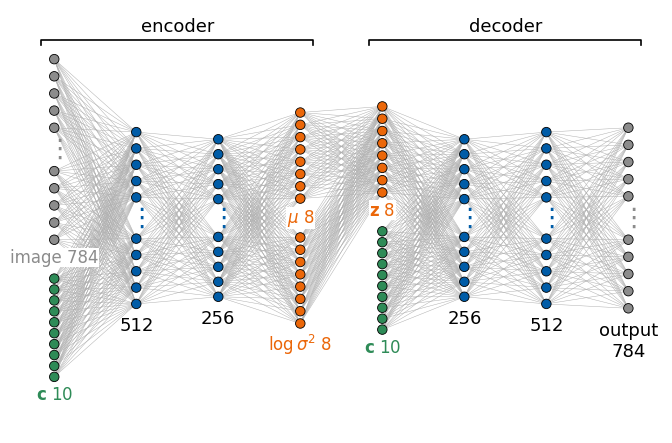

Layer (type:depth-idx)                   Output Shape              Param #
CVAE                                     [1, 784]                  --
├─Sequential: 1-1                        [1, 256]                  --
│    └─Linear: 2-1                       [1, 512]                  407,040
│    └─ReLU: 2-2                         [1, 512]                  --
│    └─Linear: 2-3                       [1, 256]                  131,328
│    └─ReLU: 2-4                         [1, 256]                  --
├─Linear: 1-2                            [1, 8]                    2,056
├─Linear: 1-3                            [1, 8]                    2,056
├─Sequential: 1-4                        [1, 784]                  --
│    └─Linear: 2-5                       [1, 256]                  4,864
│    └─ReLU: 2-6                         [1, 256]                  --
│    └─Linear: 2-7                       [1, 512]                  131,584
│    └─ReLU: 2-8                         [1, 512]            

In [ ]:
from torchinfo import summary

# helpers that read the architecture from the model instead of typing the sizes
def linear_sizes(net):
    # widths of the dense layers of a network, in order: [inputs of the first nn.Linear, outputs of each nn.Linear]
    lin = [m for m in net.modules() if isinstance(m, nn.Linear)]
    return [lin[0].in_features] + [l.out_features for l in lin]

def vae_columns(m):
    # columns of draw_network for a (conditional) VAE: input, encoder layers, (mu, log sigma^2), z, decoder layers
    enc, dec = linear_sizes(m.enc), linear_sizes(m.dec)
    first = [enc[0] - m.cond, m.cond] if m.cond else enc[0]
    zcol = [dec[0] - m.cond, m.cond] if m.cond else dec[0]
    return [first, *enc[1:], [m.mu.out_features, m.logvar.out_features], zcol, *dec[1:]]

def vae_style(cols):
    # labels, colours and brackets for the columns returned by vae_columns
    n, cond = len(cols), isinstance(cols[0], list)
    k = next(i for i in range(1, n) if isinstance(cols[i], list))          # the (mu, log sigma^2) column
    labels, colors = [None] * n, [BLUE] * n
    labels[0], colors[0] = (["image", r"$\mathbf{c}$"], [GREY, GREEN]) if cond else ("image", GREY)
    labels[k], colors[k] = [r"$\mu$", r"$\log\sigma^2$"], [ORANGE, ORANGE]
    labels[k + 1], colors[k + 1] = ([r"$\mathbf{z}$", r"$\mathbf{c}$"], [ORANGE, GREEN]) if cond else (r"$\mathbf{z}$", ORANGE)
    labels[-1], colors[-1] = "output", GREY
    groups = ([("encoder", 0, k), ("decoder", k + 1, n - 1)] if cond else
              [("encoder", 0, k), ("latent", k + 1, k + 1), ("decoder", k + 2, n - 1)])
    return dict(labels=labels, colors=colors, groups=groups, no_input=[(k + 1, 1)] if cond else None)

def dense_params(cols, sampled=()):
    # parameters of the drawn connections: a*b weights and b biases between consecutive columns,
    # except the edges into a sampled column (z = mu + sigma * eps has no parameters)
    w = lambda c: sum(c) if isinstance(c, list) else c
    return sum(w(a) * w(b) + w(b) for i, (a, b) in enumerate(zip(cols[:-1], cols[1:])) if i + 1 not in sampled)

with torch.random.fork_rng():                                    # building a model draws random weights; later cells keep their random numbers
    cvae_d8 = CVAE(d=8, cond=10)
    table = summary(cvae_d8, input_data=[torch.zeros(1, 784), torch.zeros(1, 10)], col_names=("output_size", "num_params"), verbose=0)
cols = vae_columns(cvae_d8)
print("columns read from the model:", cols)
assert dense_params(cols, sampled={len(cols) - 4}) == table.total_params   # the drawing carries exactly the parameters of the model

draw_network(cols, **vae_style(cols), x_gap=1.9)
plt.show()
print(table)

#### Training of the conditional VAE

The network is trained for 20 epochs on the 60 000 training digits with their one-hot labels and save the weights.

In [8]:
rng = seed(2); t0 = time.time()
cvae = train_vae(CVAE(d=8, cond=10), Xtr, F.one_hot(ytr, 10).float(), epochs=20)
torch.save(cvae.state_dict(), f"{RES}/cond_mnist_cvae.pt")
print(f"trained in {time.time() - t0:.0f} s")

epoch 5: loss per image 107.1 = reconstruction 93.6 + KL 13.5


epoch 10: loss per image 101.4 = reconstruction 87.5 + KL 13.9


epoch 15: loss per image 99.1 = reconstruction 85.0 + KL 14.1


epoch 20: loss per image 97.6 = reconstruction 83.4 + KL 14.2
trained in 173 s


After 20 epochs the loss per image is 97.6, with reconstruction 83.4 and KL 14.2.

### Generation of a chosen digit

Generation samples equation (5) and uses **only the decoder**. For $n$ images of digit $k$ the condition is the one-hot vector $\mathbf e_k$ of $k$, repeated $n$ times, and the style comes from $n$ random latent vectors:
$$\mathbf c=\mathbf e_k,\qquad \mathbf z\sim\mathcal N(0,I),\qquad \hat{\mathbf x}=\operatorname{sigmoid}\big(G(\mathbf z,\mathbf c)\big). \tag{6}$$
The function `generate_digit` implements equation (6).

In [9]:
def generate_digit(k, n=10):
    # n new images of digit k, shape (n, 784), pixels in [0, 1]
    c = F.one_hot(torch.full((n,), k), 10).float()            # condition: digit k, one-hot, n copies
    z = torch.randn(n, cvae.d)                                # latent vectors: the style, random
    with torch.no_grad():
        return torch.sigmoid(cvae.decode(z, c))

torch.manual_seed(30)
fig, axs = plt.subplots(10, 12, figsize=(8.4, 7.4))
for k in range(10):
    imgs = generate_digit(k, 12).reshape(-1, 28, 28).numpy()
    for j in range(12):
        axs[k, j].imshow(imgs[j], cmap="gray_r", vmin=0, vmax=1); axs[k, j].axis("off")
    axs[k, 0].text(-6, 14, f"k = {k}", ha="right", va="center", fontsize=10)
plt.subplots_adjust(wspace=0.04, hspace=0.04); plt.savefig(f"{OUT}/cond_generate_digits.png", dpi=170, bbox_inches="tight"); plt.show()

/tmp/ipykernel_3978098/2793799277.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.subplots_adjust(wspace=0.04, hspace=0.04); plt.savefig(f"{OUT}/cond_generate_digits.png", dpi=170, bbox_inches="tight"); plt.show()


Row $k$ of the figure shows `generate_digit(k, 12)`. Within a row the digit is fixed, and the style (slant, thickness, width) changes with the random $\mathbf z$.

### Classification of the synthetic digits

1000 digits of each class are generated and labelled by the classifier, which never saw a synthetic image, label them. Row $k$ of the resulting confusion matrix gives the fraction of the digits *requested* as $k$ that the classifier assigns to each class.

In [10]:
torch.manual_seed(31)
req, pred_syn = [], []
with torch.no_grad():
    for k in range(10):
        g = generate_digit(k, 1000); pred_syn += clf(g).argmax(1).tolist(); req += [k] * 1000
req, pred_syn = np.array(req), np.array(pred_syn)
cm_syn = confusion(req, pred_syn, 10)
nums["mnist_syn_agreement"] = [round(float(cm_syn[k, k]), 3) for k in range(10)]
nums["mnist_syn_agreement_mean"] = float(np.mean(nums["mnist_syn_agreement"]))
np.savez(f"{RES}/cond_mnist_confusion.npz", real=cm_real, synthetic=cm_syn)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.4))
for a, m, ttl, yl in [(axs[0], cm_real, f"real test digits: accuracy {nums['mnist_clf_real_acc']:.3f}", "true digit"),
                      (axs[1], cm_syn, f"synthetic digits: {nums['mnist_syn_agreement_mean']:.3f} as requested", "requested digit")]:
    a.imshow(m, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            if m[i, j] >= 0.01: a.text(j, i, f"{100 * m[i, j]:.0f}", ha="center", va="center", fontsize=7, color="white" if m[i, j] > 0.5 else "black")
    a.set_xticks(range(10)); a.set_yticks(range(10)); a.set_xlabel("predicted digit"); a.set_ylabel(yl); a.set_title(ttl, fontsize=11)
plt.tight_layout(); plt.savefig(f"{OUT}/cond_mnist_confusion.png", dpi=170, bbox_inches="tight"); plt.show()
print("fraction recognised as requested, per digit:", nums["mnist_syn_agreement"])

fraction recognised as requested, per digit: [0.943, 0.981, 0.952, 0.953, 0.99, 0.937, 0.93, 0.962, 0.968, 0.906]


/tmp/ipykernel_3978098/3556056146.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/cond_mnist_confusion.png", dpi=170, bbox_inches="tight"); plt.show()


The numbers in the matrices are percentages of each row. The diagonal of the right matrix says how often the generated digit is the one we asked for: between 90.6% (digit 9) and 99.0% (digit 4), 95.2% on average. The off-diagonal entries say what a generated digit is confused with, and can be compared with the confusions of the same classifier on real digits in the left matrix.

### Classifier trained on synthetic digits

A harder test is whether the synthetic digits can stand in for real ones. The same classifier architecture is trained on **60 000 synthetic digits only**, 6000 per class with the requested digits as labels, and test it on the **real** test digits.

In [11]:
torch.manual_seed(32)
Xs = torch.cat([generate_digit(k, 6000) for k in range(10)]); ys = torch.arange(10).repeat_interleave(6000)
rng = seed(3)
clf_syn = train_classifier(nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10)), Xs, ys, epochs=3)
torch.save(clf_syn.state_dict(), f"{RES}/cond_mnist_classifier_trained_on_synthetic.pt")
with torch.no_grad(): pred_s = clf_syn(Xte).argmax(1).numpy()
cm_s = confusion(yte.numpy(), pred_s, 10)
nums["mnist_train_syn_test_real_acc"] = float((pred_s == yte.numpy()).mean())
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.imshow(cm_s, cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        if cm_s[i, j] >= 0.01: ax.text(j, i, f"{100 * cm_s[i, j]:.0f}", ha="center", va="center", fontsize=7, color="white" if cm_s[i, j] > 0.5 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit")
ax.set_title(f"trained on synthetic, tested on real: {nums['mnist_train_syn_test_real_acc']:.3f}", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/cond_mnist_train_synthetic.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"real-data classifier on real test digits: {nums['mnist_clf_real_acc']:.3f}")
print(f"synthetic-data classifier on real test digits: {nums['mnist_train_syn_test_real_acc']:.3f}")

real-data classifier on real test digits: 0.969
synthetic-data classifier on real test digits: 0.918


/tmp/ipykernel_3978098/819876526.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/cond_mnist_train_synthetic.png", dpi=170, bbox_inches="tight"); plt.show()


The classifier trained on synthetic digits reaches 0.918 on real test digits, against 0.969 for the one trained on real digits. The gap measures what the generator misses of the real distribution: styles it never produces, and blurry strokes.

As an exercise, mix real and synthetic training digits, for example 1000 real and 60 000 synthetic. Does the synthetic data help when real data are scarce? Compare with 1000 real digits alone.

## Blood cells of a chosen type

BloodMNIST (Lecture 4) contains $28\times28$ images in RGB (red, green, blue) colour of eight types of normal blood cells. The file is taken from the Lecture 4 folder, or downloaded from Zenodo. The classes are unbalanced, from 849 lymphocytes to 2330 neutrophils in the training set.

In [12]:
bpath = "data/bloodmnist.npz"
if not os.path.exists(bpath):
    bpath = "data/bloodmnist.npz"
    if not os.path.exists(bpath):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve("https://zenodo.org/records/10519652/files/bloodmnist.npz?download=1", bpath)
bd = np.load(bpath)
names = ["basophil", "eosinophil", "erythroblast", "immature granulocyte", "lymphocyte", "monocyte", "neutrophil", "platelet"]
to_t = lambda a: torch.tensor(a.astype(np.float32) / 255).permute(0, 3, 1, 2)      # (n, 3, 28, 28)
Btr, Bte = to_t(bd["train_images"]), to_t(bd["test_images"])
bytr, byte = torch.tensor(bd["train_labels"].ravel().astype(np.int64)), torch.tensor(bd["test_labels"].ravel().astype(np.int64))
print("training images:", tuple(Btr.shape), " test images:", tuple(Bte.shape))
print("training images per type:", dict(zip(names, np.bincount(bytr.numpy()).tolist())))

training images: (11959, 3, 28, 28)  test images: (3421, 3, 28, 28)
training images per type: {'basophil': 852, 'eosinophil': 2181, 'erythroblast': 1085, 'immature granulocyte': 2026, 'lymphocyte': 849, 'monocyte': 993, 'neutrophil': 2330, 'platelet': 1643}


### Classifier trained on real cells

The judge for the cells is a small convolutional neural network (CNN): two blocks of $3\times3$ convolution, ReLU and $2\times2$ max-pooling ($28\to14\to7$ pixels), followed by dense layers $64\cdot7\cdot7\to128\to8$.

In [13]:
rng = seed(8)
clfb = train_classifier(nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 8)), Btr, bytr, epochs=8)
torch.save(clfb.state_dict(), f"{RES}/cond_blood_classifier.pt")
with torch.no_grad(): pb_real = clfb(Bte).argmax(1).numpy()
cmb_real = confusion(byte.numpy(), pb_real, 8)
nums["blood_clf_real_acc"] = float((pb_real == byte.numpy()).mean())
print(f"accuracy on real test cells: {nums['blood_clf_real_acc']:.3f}")

accuracy on real test cells: 0.838


The CNN reaches an accuracy of 0.838 on the real test cells.

### Convolutional conditional VAE

A convolution sees an image as stacked channels, so the condition enters as **8 extra input channels**: channel $k$ is constant, equal to 1 if the cell is of type $k$ and 0 otherwise. The encoder maps $28\times28\times(3+8)\to14\times14\times32\to7\times7\times64\to(\boldsymbol\mu,\log\boldsymbol\sigma^2)$ with 16 latent numbers. The decoder maps $[\mathbf z,\mathbf c]$ ($16+8$ numbers) $\to7\times7\times64\to14\times14\times32\to28\times28\times3$ logits, with transposed convolutions that double the size at each step.

In [14]:
class ConvCVAE(nn.Module):
    def __init__(self, d=16, cond=8):
        super().__init__()
        self.d, self.cond = d, cond
        self.enc = nn.Sequential(nn.Conv2d(3 + cond, 32, 3, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(), nn.Flatten())
        self.mu, self.logvar = nn.Linear(64 * 7 * 7, d), nn.Linear(64 * 7 * 7, d)
        self.fc = nn.Linear(d + cond, 64 * 7 * 7)
        self.dec = nn.Sequential(nn.ReLU(), nn.Unflatten(1, (64, 7, 7)), nn.ConvTranspose2d(64, 32, 3, 2, 1, output_padding=1), nn.ReLU(),
                                 nn.ConvTranspose2d(32, 3, 3, 2, 1, output_padding=1))
    def encode(self, x, c):
        cmap_ = c[:, :, None, None].expand(-1, -1, x.shape[2], x.shape[3])        # the condition as 8 constant channels
        h = self.enc(torch.cat([x, cmap_], 1)); return self.mu(h), self.logvar(h)
    def decode(self, z, c): return self.dec(self.fc(torch.cat([z, c], 1)))       # logits of the pixels
    def forward(self, x, c):
        mu, logvar = self.encode(x, c); z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decode(z, c), mu, logvar

rng = seed(7); t0 = time.time()
bcvae = ConvCVAE(); optb = torch.optim.Adam(bcvae.parameters(), 1e-3); Cb = F.one_hot(bytr, 8).float()
for ep in range(30):
    perm = torch.randperm(len(Btr)); tot = np.zeros(3)
    for i in range(0, len(perm), 128):
        j = perm[i:i + 128]; logits, mu, logvar = bcvae(Btr[j], Cb[j])
        loss, rec, kl = vae_loss(logits.flatten(1), Btr[j].flatten(1), mu, logvar)
        optb.zero_grad(); loss.backward(); optb.step()
        tot += np.array([loss.item(), rec.item(), kl.item()]) * len(j)
    if ep % 10 == 9: print(f"epoch {ep + 1}: loss per image {tot[0] / len(Btr):.1f} = reconstruction {tot[1] / len(Btr):.1f} + KL {tot[2] / len(Btr):.1f}")
bcvae.eval(); torch.save(bcvae.state_dict(), f"{RES}/cond_blood_cvae.pt")
print(f"trained in {time.time() - t0:.0f} s")

epoch 10: loss per image 1210.0 = reconstruction 1194.9 + KL 15.1


epoch 20: loss per image 1205.2 = reconstruction 1190.0 + KL 15.2


epoch 30: loss per image 1203.4 = reconstruction 1188.1 + KL 15.3
trained in 124 s


#### Convolutional conditional VAE architecture

A convolutional network is not a stack of dense layers, so `draw_network` does not apply; the two libraries show it instead. The `torchinfo` table follows the shapes through the network: the $3+8$ input channels of $28\times28$ pixels become 32 channels of $14\times14$ and 64 channels of $7\times7$, which are flattened to 3136 numbers ($64\cdot7\cdot7$) and mapped to $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$ of size 16. In the decoder a dense layer maps the $16+8$ numbers back to 3136, and two transposed convolutions grow the image to $28\times28$ with 3 colour channels. Of the 219,811 parameters, most sit in the three dense layers that connect to the 3136 flattened features.

`torchview.draw_graph(model, input_data=..., expand_nested=True)` follows one forward pass and draws it as a graph: each box is a module or a tensor operation with the shapes of its input and output, and `expand_nested=True` shows the contents of the `nn.Sequential` containers of encoder and decoder inside frames. The graph is rendered to a PNG file with Graphviz (`results/arch_convcvae_torchview.png`). In it we can see the condition expanded to 8 constant channels and joined to the image by `cat`, and joined again to $\mathbf z$ before the decoder.

Layer (type:depth-idx)                   Output Shape              Param #
ConvCVAE                                 [1, 3, 28, 28]            --
├─Sequential: 1-1                        [1, 3136]                 --
│    └─Conv2d: 2-1                       [1, 32, 14, 14]           3,200
│    └─ReLU: 2-2                         [1, 32, 14, 14]           --
│    └─Conv2d: 2-3                       [1, 64, 7, 7]             18,496
│    └─ReLU: 2-4                         [1, 64, 7, 7]             --
│    └─Flatten: 2-5                      [1, 3136]                 --
├─Linear: 1-2                            [1, 16]                   50,192
├─Linear: 1-3                            [1, 16]                   50,192
├─Linear: 1-4                            [1, 3136]                 78,400
├─Sequential: 1-5                        [1, 3, 28, 28]            --
│    └─ReLU: 2-6                         [1, 3136]                 --
│    └─Unflatten: 2-7                    [1, 64, 7, 7]            

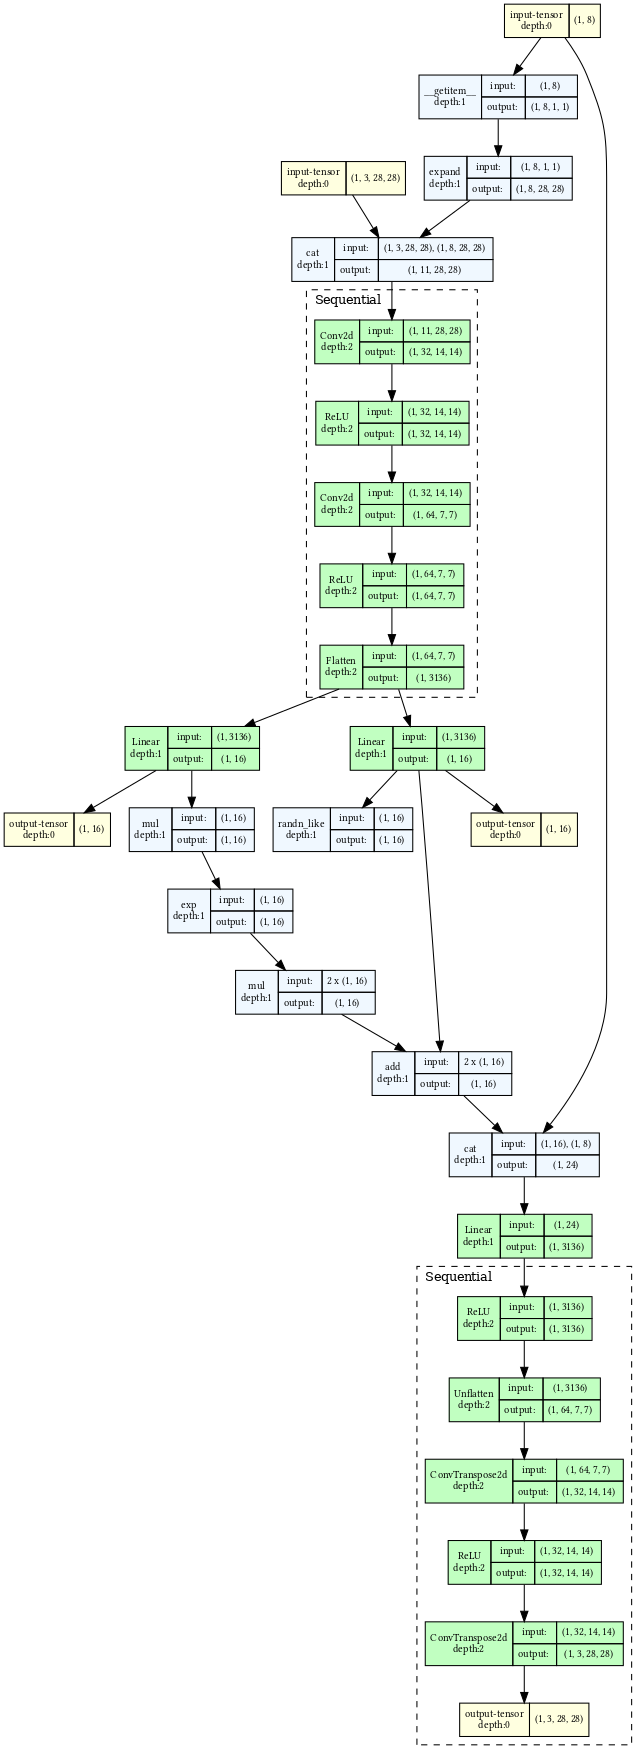

In [ ]:
from torchview import draw_graph
from IPython.display import Image, display

x_ex, c_ex = torch.zeros(1, 3, 28, 28), torch.zeros(1, 8)        # one example image and one one-hot cell type
with torch.random.fork_rng():
    print(summary(ConvCVAE(), input_data=[x_ex, c_ex], col_names=("output_size", "num_params"), verbose=0))
    graph = draw_graph(ConvCVAE(), input_data=[x_ex, c_ex], expand_nested=True, graph_name="ConvCVAE")
png = graph.visual_graph.render(filename="arch_convcvae_torchview", directory=RES, format="png", cleanup=True)
display(Image(png))

After 30 epochs the loss per image is 1203.4, with reconstruction 1188.1 and KL 15.3; the reconstruction term is much larger than for digits because it is summed over $3\times784$ colour values.

### Generation of a cell of a chosen type

Generation takes the same three operations as for digits: a one-hot condition, a random $\mathbf z$, and the decoder followed by the sigmoid.

In [15]:
def generate_cell(name, n=8):
    # n new 28 x 28 RGB images of the cell type `name`, shape (n, 3, 28, 28), values in [0, 1]
    k = names.index(name)
    c = F.one_hot(torch.full((n,), k), 8).float()             # condition: cell type k, one-hot
    z = torch.randn(n, bcvae.d)                               # latent vectors, random
    with torch.no_grad():
        return torch.sigmoid(bcvae.decode(z, c))

torch.manual_seed(33)
# one real example of each type, then 8 generated ones
fig, axs = plt.subplots(8, 10, figsize=(8.6, 7.4), gridspec_kw=dict(width_ratios=[1, 0.25] + [1] * 8))
for k, nm in enumerate(names):
    real = Btr[(bytr == k).nonzero()[0, 0]].permute(1, 2, 0).numpy()
    axs[k, 0].imshow(real); axs[k, 1].axis("off")
    for j, im in enumerate(generate_cell(nm, 8).permute(0, 2, 3, 1).numpy()):
        axs[k, j + 2].imshow(im)
    axs[k, 0].text(-3, 14, nm, ha="right", va="center", fontsize=9)
    for a in axs[k]: a.set_xticks([]); a.set_yticks([])
    for a in axs[k, 2:]: a.axis("off")
axs[0, 0].set_title("real", fontsize=9); axs[0, 2].set_title("generated: generate_cell(name, 8)", fontsize=9, loc="left")
plt.subplots_adjust(wspace=0.04, hspace=0.06); plt.savefig(f"{OUT}/cond_generate_cells.png", dpi=170, bbox_inches="tight"); plt.show()

/tmp/ipykernel_3978098/3079786119.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.subplots_adjust(wspace=0.04, hspace=0.06); plt.savefig(f"{OUT}/cond_generate_cells.png", dpi=170, bbox_inches="tight"); plt.show()


### Classification of the synthetic cells

As for the digits, 500 cells of each type are generated and labelled by the CNN trained on real cells, and compare the resulting confusion matrix with that of the same CNN on real test cells.

In [16]:
torch.manual_seed(34)
reqb, pb_syn = [], []
with torch.no_grad():
    for k, nm in enumerate(names):
        pb_syn += clfb(generate_cell(nm, 500)).argmax(1).tolist(); reqb += [k] * 500
cmb_syn = confusion(np.array(reqb), np.array(pb_syn), 8)
nums["blood_syn_agreement"] = {nm: round(float(cmb_syn[k, k]), 3) for k, nm in enumerate(names)}
nums["blood_syn_agreement_mean"] = float(np.mean(np.diag(cmb_syn)))
np.savez(f"{RES}/cond_blood_confusion.npz", real=cmb_real, synthetic=cmb_syn)

short = ["baso", "eosino", "erythro", "imm. gran.", "lympho", "mono", "neutro", "platelet"]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
for a, m, ttl, yl in [(axs[0], cmb_real, f"real test cells: accuracy {nums['blood_clf_real_acc']:.3f}", "true type"),
                      (axs[1], cmb_syn, f"synthetic cells: {nums['blood_syn_agreement_mean']:.3f} as requested", "requested type")]:
    a.imshow(m, cmap="Blues", vmin=0, vmax=1)
    for i in range(8):
        for j in range(8):
            if m[i, j] >= 0.01: a.text(j, i, f"{100 * m[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if m[i, j] > 0.5 else "black")
    a.set_xticks(range(8)); a.set_xticklabels(short, rotation=45, ha="right", fontsize=9)
    a.set_yticks(range(8)); a.set_yticklabels(short, fontsize=9); a.set_xlabel("predicted type"); a.set_ylabel(yl); a.set_title(ttl, fontsize=11)
plt.tight_layout(); plt.savefig(f"{OUT}/cond_blood_confusion.png", dpi=170, bbox_inches="tight"); plt.show()
print("fraction recognised as requested:", nums["blood_syn_agreement"])

fraction recognised as requested: {'basophil': 0.062, 'eosinophil': 0.822, 'erythroblast': 0.962, 'immature granulocyte': 0.818, 'lymphocyte': 0.142, 'monocyte': 0.182, 'neutrophil': 0.116, 'platelet': 1.0}


/tmp/ipykernel_3978098/1613527970.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/cond_blood_confusion.png", dpi=170, bbox_inches="tight"); plt.show()


The two diagonals differ strongly. Types that differ in size and colour are generated recognisably: platelets 100%, erythroblasts 96.2%, eosinophils 82.2%, immature granulocytes 81.8%. Types that differ in the shape of the nucleus are not: basophils 6.2%, neutrophils 11.6%, lymphocytes 14.2%, monocytes 18.2%. The VAE blurs exactly the detail the classifier relies on, and the off-diagonal entries show which type these cells collapse to.

### Classifier trained on synthetic cells

As for the digits, the same CNN is trained on 12 000 generated cells, 1500 per type with the requested types as labels, and test it on the real test cells.

In [17]:
torch.manual_seed(35)
Bs = torch.cat([generate_cell(nm, 1500) for nm in names]); ybs = torch.arange(8).repeat_interleave(1500)
rng = seed(9)
clfb_syn = train_classifier(nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                          nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 8)), Bs, ybs, epochs=8)
torch.save(clfb_syn.state_dict(), f"{RES}/cond_blood_classifier_trained_on_synthetic.pt")
with torch.no_grad(): pbs = clfb_syn(Bte).argmax(1).numpy()
cmb_s = confusion(byte.numpy(), pbs, 8)
nums["blood_train_syn_test_real_acc"] = float((pbs == byte.numpy()).mean())
nums["blood_train_syn_test_real_per_type"] = {nm: round(float(cmb_s[k, k]), 3) for k, nm in enumerate(names)}
print(f"real-data CNN on real test cells: {nums['blood_clf_real_acc']:.3f}")
print(f"synthetic-data CNN on real test cells: {nums['blood_train_syn_test_real_acc']:.3f}")
print("per type:", nums["blood_train_syn_test_real_per_type"])

real-data CNN on real test cells: 0.838
synthetic-data CNN on real test cells: 0.637
per type: {'basophil': 0.816, 'eosinophil': 0.635, 'erythroblast': 0.646, 'immature granulocyte': 0.38, 'lymphocyte': 0.827, 'monocyte': 0.317, 'neutrophil': 0.643, 'platelet': 0.947}


The CNN trained on synthetic cells reaches 0.637 on real test cells, against 0.838 for the one trained on real cells. Per type, the accuracy ranges from 0.317 (monocytes) to 0.947 (platelets).

## Real and synthetic data for training and testing

The experiments above combine real and synthetic data in different ways. Collecting all four combinations of training and test data, for each data set, gives a compact summary. The synthetic test sets are freshly generated (1000 digits per class, 500 cells per type) and never used in training. Each cell of the table answers a different question:

| | tested on real | tested on synthetic |
|---|---|---|
| **trained on real** | how good the classifier is | is the requested class recognisable? |
| **trained on synthetic** | can synthetic data replace real data? | does the generator separate the classes it was asked for? |

In [18]:
torch.manual_seed(36)
Xs_te = torch.cat([generate_digit(k, 1000) for k in range(10)]); ys_te = torch.arange(10).repeat_interleave(1000)
Bs_te = torch.cat([generate_cell(nm, 500) for nm in names]); ybs_te = torch.arange(8).repeat_interleave(500)
def acc(model, X, y):
    with torch.no_grad(): return float((model(X).argmax(1) == y).float().mean())
table = {"MNIST": np.array([[acc(clf, Xte, yte), acc(clf, Xs_te, ys_te)], [acc(clf_syn, Xte, yte), acc(clf_syn, Xs_te, ys_te)]]),
         "BloodMNIST": np.array([[acc(clfb, Bte, byte), acc(clfb, Bs_te, ybs_te)], [acc(clfb_syn, Bte, byte), acc(clfb_syn, Bs_te, ybs_te)]])}
nums["two_by_two"] = {k: v.round(3).tolist() for k, v in table.items()}
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
for a, (name, m) in zip(axs, table.items()):
    a.imshow(m, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2): a.text(j, i, f"{m[i, j]:.3f}", ha="center", va="center", fontsize=15, color="white" if m[i, j] > 0.6 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["tested on real", "tested on synthetic"], fontsize=11)
    a.set_yticks([0, 1]); a.set_yticklabels(["trained on real", "trained on synthetic"], fontsize=11)
    a.set_title(f"{name}: accuracy", fontsize=12)
plt.tight_layout(); plt.savefig(f"{OUT}/cond_two_by_two.png", dpi=170, bbox_inches="tight"); plt.show()
for k, v in table.items(): print(k, "\n", v.round(3))

MNIST 
 [[0.969 0.955]
 [0.918 0.986]]
BloodMNIST 
 [[0.838 0.514]
 [0.637 0.864]]


/tmp/ipykernel_3978098/3929926398.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/cond_two_by_two.png", dpi=170, bbox_inches="tight"); plt.show()


The table is read by rows. A classifier trained on real data and tested on synthetic data measures whether the generator draws the requested class: 0.955 for MNIST, but only 0.514 for BloodMNIST. A classifier trained on synthetic data and tested on real data measures whether the synthetic data carry what is needed to recognise real instances: 0.918 and 0.637. For BloodMNIST, the high synthetic/synthetic accuracy of 0.864 together with the low synthetic/real accuracy of 0.637 means that the generator produces classes that are easy to tell apart, but not the real ones.

As an exercise, mix real and synthetic training cells: 10% of the real training set plus all synthetic cells. Does the synthetic data help when real data are scarce?

Finally, the numbers computed above are written to `results/numbers_cond.json`, from which the slides take their values.

In [19]:
json.dump(nums, open(f"{RES}/numbers_cond.json", "w"), indent=1)
print(json.dumps(nums, indent=1))

{
 "vae2_mean_sigma": 0.040771543979644775,
 "vae2_frac_within_1": 0.4876,
 "vae2_frac_within_2": 0.7966,
 "vae2_frac_within_3": 0.9651,
 "mnist_clf_real_acc": 0.9692,
 "mnist_syn_agreement": [
  0.943,
  0.981,
  0.952,
  0.953,
  0.99,
  0.937,
  0.93,
  0.962,
  0.968,
  0.906
 ],
 "mnist_syn_agreement_mean": 0.9522,
 "mnist_train_syn_test_real_acc": 0.9179,
 "blood_clf_real_acc": 0.8380590470622625,
 "blood_syn_agreement": {
  "basophil": 0.062,
  "eosinophil": 0.822,
  "erythroblast": 0.962,
  "immature granulocyte": 0.818,
  "lymphocyte": 0.142,
  "monocyte": 0.182,
  "neutrophil": 0.116,
  "platelet": 1.0
 },
 "blood_syn_agreement_mean": 0.5129999999999999,
 "blood_train_syn_test_real_acc": 0.6372405729318913,
 "blood_train_syn_test_real_per_type": {
  "basophil": 0.816,
  "eosinophil": 0.635,
  "erythroblast": 0.646,
  "immature granulocyte": 0.38,
  "lymphocyte": 0.827,
  "monocyte": 0.317,
  "neutrophil": 0.643,
  "platelet": 0.947
 },
 "two_by_two": {
  "MNIST": [
   [
    0